# Heart murmur detection from phonocardiogram audio (CirCor DigiScope)
Binary task: murmur **Present** vs **Absent**, from heart sound audio only. Clinical columns (age, height, grading, pitch...) are never used as model inputs.
Split is by **patient**, so no patient appears in more than one of train, validation and test.

In [1]:
%%writefile preprocessing.py
"""Heart sound preprocessing. One module shared by the notebook, the API and retraining."""
import numpy as np
import librosa
from scipy.signal import butter, sosfiltfilt

SR = 4000                  # target sample rate (Hz)
LOW_HZ, HIGH_HZ = 25, 500  # band-pass range for heart sounds and murmurs
WIN_SEC = 5.0              # window length
HOP_SEC = 5.0              # hop between windows (non-overlapping)
MIN_SEC = 1.5              # recordings shorter than this are skipped
N_MELS, N_FFT, HOP_LENGTH = 64, 512, 128

_SOS = butter(4, [LOW_HZ, HIGH_HZ], btype="bandpass", fs=SR, output="sos")


def load_audio(path):
    y, _ = librosa.load(path, sr=SR, mono=True)
    return y.astype(np.float32)


def bandpass(y):
    return sosfiltfilt(_SOS, y).astype(np.float32)


def split_windows(y, max_windows=None):
    """Cut a recording into fixed-length windows. The last partial window is zero-padded
    only if it holds at least MIN_SEC of signal. Returns an array (n_windows, win_samples)."""
    win, hop, min_len = int(WIN_SEC * SR), int(HOP_SEC * SR), int(MIN_SEC * SR)
    if len(y) < min_len:
        return np.empty((0, win), dtype=np.float32)
    windows = []
    for start in range(0, len(y), hop):
        seg = y[start:start + win]
        if len(seg) < win:
            if len(seg) < min_len and windows:
                break
            seg = np.pad(seg, (0, win - len(seg)))
        windows.append(seg)
        if max_windows and len(windows) >= max_windows:
            break
    return np.stack(windows).astype(np.float32)


def to_logmel(window):
    """One window -> standardised log-mel spectrogram of shape (N_MELS, frames)."""
    m = librosa.feature.melspectrogram(
        y=window, sr=SR, n_fft=N_FFT, hop_length=HOP_LENGTH,
        n_mels=N_MELS, fmin=LOW_HZ, fmax=HIGH_HZ, power=2.0)
    db = librosa.power_to_db(m, ref=1.0, top_db=80.0)
    return ((db - db.mean()) / (db.std() + 1e-6)).astype(np.float32)


def wav_to_features(path, max_windows=None):
    """.wav path -> array (n_windows, N_MELS, frames, 1). Empty array if too short."""
    y = bandpass(load_audio(path))
    wins = split_windows(y, max_windows)
    if len(wins) == 0:
        return np.empty((0, N_MELS, 1 + int(WIN_SEC * SR) // HOP_LENGTH, 1), dtype=np.float32)
    return np.stack([to_logmel(w) for w in wins])[..., None]


Writing preprocessing.py


In [2]:
import os, glob, json
import numpy as np, pandas as pd
from joblib import Parallel, delayed
from sklearn.model_selection import train_test_split
import preprocessing as P

SEED = 42
DATA_ROOT = "/kaggle/input/datasets/bjoernjostein/the-circor-digiscope-phonocardiogram-dataset-v2"
OUT_DIR = "/kaggle/working/processed"
MAX_WINDOWS_PER_REC = 8
# If True, a recording from a murmur-Present patient is kept (label 1) only when its
# auscultation location is listed in that patient's "Murmur locations". Otherwise the
# murmur may be inaudible at that spot and the patient-level label would be wrong for it.
RESTRICT_TO_MURMUR_LOCATIONS = True
os.makedirs(OUT_DIR, exist_ok=True)

wavs = sorted(glob.glob(os.path.join(DATA_ROOT, "**", "*.wav"), recursive=True))
print(len(wavs), "wav files found")
if not wavs:
    for root, dirs, files in os.walk(DATA_ROOT):
        print(root, files[:3]); break
    raise SystemExit("No .wav files under DATA_ROOT. Check the dataset path above.")
print(wavs[:3])

3163 wav files found
['/kaggle/input/datasets/bjoernjostein/the-circor-digiscope-phonocardiogram-dataset-v2/training_data/training_data/13918_AV.wav', '/kaggle/input/datasets/bjoernjostein/the-circor-digiscope-phonocardiogram-dataset-v2/training_data/training_data/13918_MV.wav', '/kaggle/input/datasets/bjoernjostein/the-circor-digiscope-phonocardiogram-dataset-v2/training_data/training_data/13918_PV.wav']


In [4]:
# ---- metadata and recording-level labels ----
meta = pd.read_csv(os.path.join(DATA_ROOT, "training_data.csv"))
meta.columns = [c.strip() for c in meta.columns]
meta = meta[["Patient ID", "Murmur", "Murmur locations"]].rename(
    columns={"Patient ID": "patient_id", "Murmur": "murmur", "Murmur locations": "murmur_locs"})
print(meta["murmur"].value_counts(dropna=False))

recs = []
for p in wavs:
    parts = os.path.splitext(os.path.basename(p))[0].split("_")
    if parts[0].isdigit() and len(parts) > 1:
        recs.append({"path": p, "patient_id": int(parts[0]), "site": parts[1]})
recs = pd.DataFrame(recs).merge(meta, on="patient_id", how="inner")

def rec_label(r):
    if r.murmur == "Absent":
        return 0
    if r.murmur == "Present":
        if not RESTRICT_TO_MURMUR_LOCATIONS:
            return 1
        locs = str(r.murmur_locs).split("+") if isinstance(r.murmur_locs, str) else []
        return 1 if r.site in locs else -1      # -1 = ambiguous, dropped
    return -1                                   # Unknown, dropped

recs["label"] = recs.apply(rec_label, axis=1)
print("dropped (Unknown or ambiguous location):", (recs.label == -1).sum(), "of", len(recs))
recs = recs[recs.label >= 0].reset_index(drop=True)
print(recs.label.value_counts())

murmur
Absent     695
Present    179
Unknown     68
Name: count, dtype: int64
dropped (Unknown or ambiguous location): 273 of 3163
label
0    2391
1     499
Name: count, dtype: int64


In [5]:
# ---- patient-wise split (70 / 15 / 15), stratified on patient-level murmur label ----
pat = recs.groupby("patient_id")["murmur"].first().reset_index()
tr_p, tmp_p = train_test_split(pat, test_size=0.30, stratify=pat["murmur"], random_state=SEED)
va_p, te_p = train_test_split(tmp_p, test_size=0.50, stratify=tmp_p["murmur"], random_state=SEED)
split_of = {**{i: "train" for i in tr_p.patient_id}, **{i: "val" for i in va_p.patient_id},
            **{i: "test" for i in te_p.patient_id}}
recs["split"] = recs["patient_id"].map(split_of)

# leakage check: no patient in more than one split
assert recs.groupby("patient_id")["split"].nunique().max() == 1
print(recs.groupby("split").agg(patients=("patient_id", "nunique"), recordings=("path", "count"),
                                murmur_rate=("label", "mean")).round(3))

       patients  recordings  murmur_rate
split                                   
test        132         459        0.174
train       611        2010        0.173
val         131         421        0.169


In [6]:
# ---- feature extraction (runs once, saved to disk) ----
def extract(i, path):
    return i, P.wav_to_features(path, max_windows=MAX_WINDOWS_PER_REC)

results = Parallel(n_jobs=-1, verbose=5)(delayed(extract)(i, r.path) for i, r in recs.iterrows())

for split in ["train", "val", "test"]:
    X, y, rec_id, pat_id = [], [], [], []
    for i, feats in results:
        r = recs.loc[i]
        if r.split != split or len(feats) == 0:
            continue
        X.append(feats.astype(np.float16)); n = len(feats)
        y += [r.label] * n; rec_id += [i] * n; pat_id += [r.patient_id] * n
    X = np.concatenate(X)
    np.savez_compressed(f"{OUT_DIR}/{split}.npz", X=X, y=np.array(y), rec_id=np.array(rec_id),
                        patient_id=np.array(pat_id))
    print(split, X.shape, "murmur windows:", int(np.sum(y)), "of", len(y))
recs.drop(columns=["path"]).to_csv(f"{OUT_DIR}/recordings.csv", index=False)

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=-1)]: Done  10 tasks      | elapsed:   27.8s
[Parallel(n_jobs=-1)]: Done  80 tasks      | elapsed:   29.3s
[Parallel(n_jobs=-1)]: Done 260 tasks      | elapsed:   33.5s
[Parallel(n_jobs=-1)]: Done 512 tasks      | elapsed:   39.0s
[Parallel(n_jobs=-1)]: Done 836 tasks      | elapsed:   46.3s
[Parallel(n_jobs=-1)]: Done 1232 tasks      | elapsed:   55.2s
[Parallel(n_jobs=-1)]: Done 1700 tasks      | elapsed:  1.1min
[Parallel(n_jobs=-1)]: Done 2240 tasks      | elapsed:  1.3min
[Parallel(n_jobs=-1)]: Done 2852 tasks      | elapsed:  1.5min
[Parallel(n_jobs=-1)]: Done 2890 out of 2890 | elapsed:  1.5min finished


train (9562, 64, 157, 1) murmur windows: 1633 of 9562
val (1948, 64, 157, 1) murmur windows: 323 of 1948
test (2118, 64, 157, 1) murmur windows: 352 of 2118


## Load processed data
Everything below runs on the saved spectrograms, so this part can be rerun without repeating extraction.

In [7]:
import time, shutil
import matplotlib
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score,
                             recall_score, classification_report, confusion_matrix,
                             roc_curve, precision_recall_curve)
import librosa

tf.keras.utils.set_random_seed(SEED)
FIG_DIR = "/kaggle/working/figures"
os.makedirs(FIG_DIR, exist_ok=True)

D = {s: np.load(f"{OUT_DIR}/{s}.npz") for s in ["train", "val", "test"]}
Xtr, ytr = D["train"]["X"], D["train"]["y"].astype("float32")
Xva, yva = D["val"]["X"], D["val"]["y"].astype("float32")
Xte, yte = D["test"]["X"], D["test"]["y"].astype("float32")
print(Xtr.shape, Xva.shape, Xte.shape)

cw = compute_class_weight("balanced", classes=np.array([0., 1.]), y=ytr)
class_weight = {0: float(cw[0]), 1: float(cw[1])}
print("class weights:", class_weight)

def make_ds(X, y, shuffle=False, bs=64):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if shuffle:
        ds = ds.shuffle(4096, seed=SEED)
    return ds.batch(bs).map(lambda a, b: (tf.cast(a, tf.float32), b)).prefetch(tf.data.AUTOTUNE)

(9562, 64, 157, 1) (1948, 64, 157, 1) (2118, 64, 157, 1)
class weights: {0: 0.602976415689242, 1: 2.9277403551745254}


## Data visualizations
Four views of the dataset. Write a short interpretation under each one after looking at your own output.

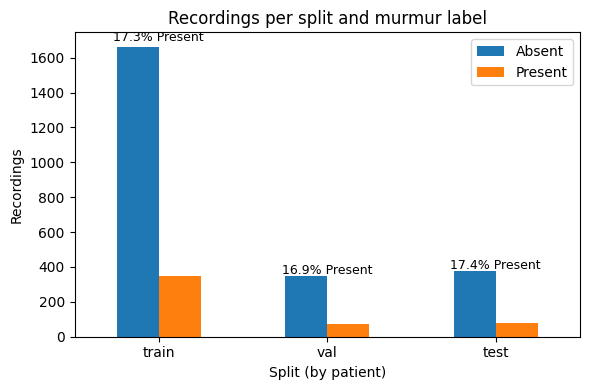

       Absent  Present
split                 
train    1662      348
val       350       71
test      379       80


In [8]:
# Figure 1: class balance per split (recordings)
ct = recs.groupby(["split", "label"]).size().unstack(fill_value=0).loc[["train", "val", "test"]]
ct.columns = ["Absent", "Present"]
fig, ax = plt.subplots(figsize=(6, 4))
ct.plot.bar(ax=ax, rot=0)
for i, s in enumerate(ct.index):
    ax.text(i, ct.loc[s].max() * 1.02, f"{ct.loc[s, 'Present'] / ct.loc[s].sum():.1%} Present", ha="center", fontsize=9)
ax.set_ylabel("Recordings"); ax.set_xlabel("Split (by patient)"); ax.set_title("Recordings per split and murmur label")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig1_class_balance.png", dpi=150); plt.show()
print(ct)

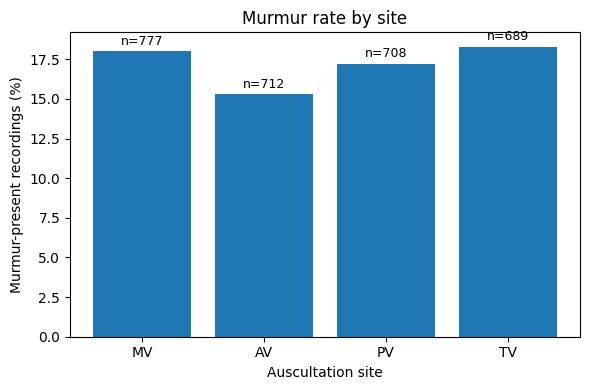

       rate    n
site            
MV    0.180  777
AV    0.153  712
PV    0.172  708
TV    0.183  689


In [9]:
# Figure 2: murmur rate by auscultation site (recordings kept after the label rule)
site = recs.groupby("site")["label"].agg(rate="mean", n="count")
site = site[site["n"] >= 20].sort_values("n", ascending=False)
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(site.index, site["rate"] * 100)
for i, s in enumerate(site.index):
    ax.text(i, site.loc[s, "rate"] * 100 + 0.4, f"n={int(site.loc[s, 'n'])}", ha="center", fontsize=9)
ax.set_ylabel("Murmur-present recordings (%)"); ax.set_xlabel("Auscultation site")
ax.set_title("Murmur rate by site")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig2_murmur_by_site.png", dpi=150); plt.show()
print(site.round(3))

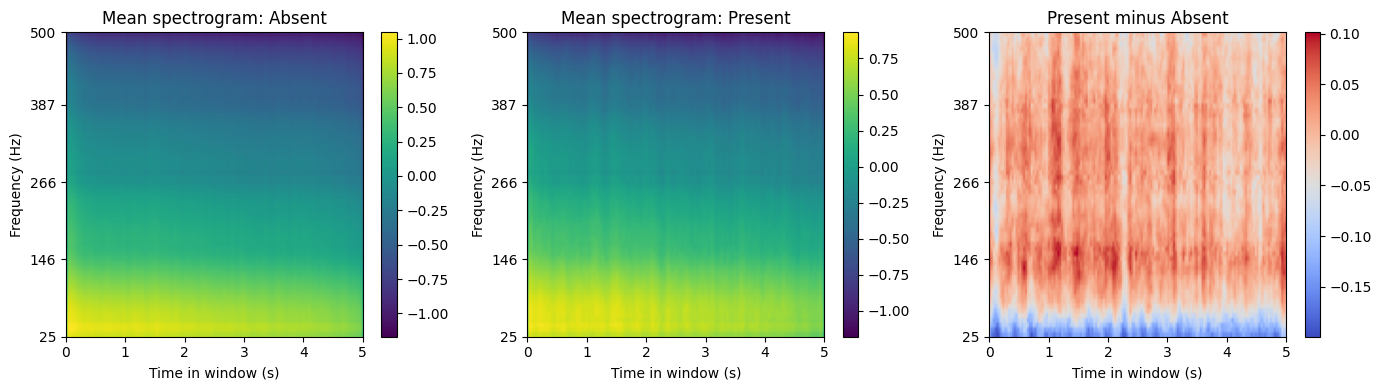

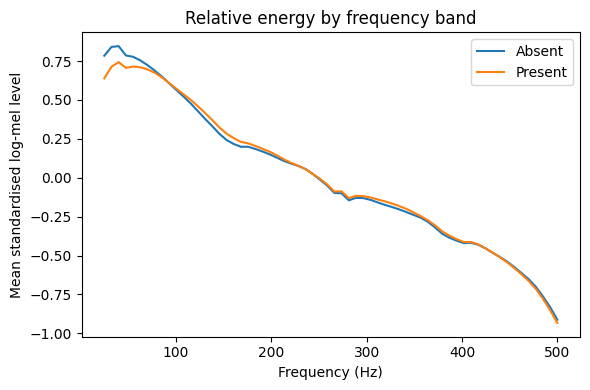

In [10]:
# Figures 3 and 4: what the spectrograms look like for each class (training windows)
mel_hz = librosa.mel_frequencies(n_mels=P.N_MELS, fmin=P.LOW_HZ, fmax=P.HIGH_HZ)
Xf = Xtr.astype("float32")[..., 0]
m0, m1 = Xf[ytr == 0].mean(0), Xf[ytr == 1].mean(0)
ticks = [0, 16, 32, 48, P.N_MELS - 1]
fig, axs = plt.subplots(1, 3, figsize=(14, 4))
for ax, img, title, cmap in [(axs[0], m0, "Mean spectrogram: Absent", "viridis"),
                             (axs[1], m1, "Mean spectrogram: Present", "viridis"),
                             (axs[2], m1 - m0, "Present minus Absent", "coolwarm")]:
    im = ax.imshow(img, origin="lower", aspect="auto", extent=[0, P.WIN_SEC, 0, P.N_MELS - 1], cmap=cmap)
    ax.set_yticks(ticks); ax.set_yticklabels([f"{mel_hz[t]:.0f}" for t in ticks])
    ax.set_xlabel("Time in window (s)"); ax.set_ylabel("Frequency (Hz)"); ax.set_title(title)
    plt.colorbar(im, ax=ax)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig3_mean_spectrograms.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(mel_hz, m0.mean(1), label="Absent"); ax.plot(mel_hz, m1.mean(1), label="Present")
ax.set_xlabel("Frequency (Hz)"); ax.set_ylabel("Mean standardised log-mel level"); ax.legend()
ax.set_title("Relative energy by frequency band")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig4_band_profile.png", dpi=150); plt.show()

**Interpretation of Figure 1:** _write after running_

**Interpretation of Figure 2:** _write after running_

**Interpretation of Figures 3 and 4:** _write after running_

## Experiments
Three CNN variants trained under the same protocol (same split, seed, class weights and early stopping).
The variant with the best **validation recording-level PR-AUC** is selected. Test data is not used for selection.

In [12]:
def build_cnn(input_shape, filters=(16, 32, 64), dropout=0.3):
    inp = keras.Input(shape=input_shape)
    x = inp
    for f in filters:
        x = layers.Conv2D(f, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.ReLU()(x)
        x = layers.MaxPool2D(2)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout)(x)
    out = layers.Dense(1, activation="sigmoid")(x)
    return keras.Model(inp, out)

def predict(m, X):
    return m.predict(make_ds(X, np.zeros(len(X), "float32")), verbose=0).ravel()

def per_recording(p, y, rec_id):
    df = pd.DataFrame({"p": p, "y": y, "rec": rec_id}).groupby("rec").agg(p=("p", "mean"), y=("y", "first"))
    return df["p"].values, df["y"].values.astype(int)

CONFIGS = {
    "A_base": dict(filters=(16, 32, 64), dropout=0.3, lr=1e-3),
    "B_wide": dict(filters=(32, 64, 128), dropout=0.4, lr=1e-3),
    "C_deep": dict(filters=(16, 32, 64, 128), dropout=0.3, lr=1e-3),
}

def run_experiment(name, cfg):
    tf.keras.utils.set_random_seed(SEED)
    m = build_cnn(Xtr.shape[1:], cfg["filters"], cfg["dropout"])
    m.compile(optimizer=keras.optimizers.Adam(cfg["lr"]), loss="binary_crossentropy",
              metrics=[keras.metrics.AUC(name="auc"), keras.metrics.AUC(curve="PR", name="pr_auc")])
    cbs = [keras.callbacks.EarlyStopping(monitor="val_pr_auc", mode="max", patience=6, restore_best_weights=True),
           keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3)]
    t0 = time.time()
    h = m.fit(make_ds(Xtr, ytr, shuffle=True), validation_data=make_ds(Xva, yva), epochs=40,
              class_weight=class_weight, callbacks=cbs, verbose=0)
    pva = predict(m, Xva)
    rp, ry = per_recording(pva, yva, D["val"]["rec_id"])
    best = int(np.argmax(h.history["val_pr_auc"]))
    row = {"name": name, "params": m.count_params(), "epochs_run": len(h.history["loss"]), "best_epoch": best + 1,
           "train_pr_auc": round(h.history["pr_auc"][best], 3), "val_window_pr_auc": round(average_precision_score(yva, pva), 3),
           "val_rec_roc_auc": round(roc_auc_score(ry, rp), 3), "val_rec_pr_auc": round(average_precision_score(ry, rp), 3),
           "minutes": round((time.time() - t0) / 60, 1)}
    print(row)
    return row, m, h

models, histories, rows = {}, {}, []
for name, cfg in CONFIGS.items():
    row, models[name], histories[name] = run_experiment(name, cfg)
    rows.append(row)
results = pd.DataFrame(rows)
results

{'name': 'A_base', 'params': 23697, 'epochs_run': 32, 'best_epoch': 26, 'train_pr_auc': 0.804, 'val_window_pr_auc': np.float64(0.612), 'val_rec_roc_auc': np.float64(0.829), 'val_rec_pr_auc': np.float64(0.703), 'minutes': 1.5}
{'name': 'B_wide', 'params': 93473, 'epochs_run': 32, 'best_epoch': 26, 'train_pr_auc': 0.843, 'val_window_pr_auc': np.float64(0.643), 'val_rec_roc_auc': np.float64(0.843), 'val_rec_pr_auc': np.float64(0.717), 'minutes': 2.6}
{'name': 'C_deep', 'params': 98001, 'epochs_run': 15, 'best_epoch': 9, 'train_pr_auc': 0.893, 'val_window_pr_auc': np.float64(0.68), 'val_rec_roc_auc': np.float64(0.894), 'val_rec_pr_auc': np.float64(0.762), 'minutes': 0.9}


,name,params,epochs_run,best_epoch,train_pr_auc,val_window_pr_auc,val_rec_roc_auc,val_rec_pr_auc,minutes
0,A_base,23697,32,26,0.804,0.612,0.829,0.703,1.5
1,B_wide,93473,32,26,0.843,0.643,0.843,0.717,2.6
2,C_deep,98001,15,9,0.893,0.680,0.894,0.762,0.9


In [13]:
best_name = results.sort_values("val_rec_pr_auc").iloc[-1]["name"]
model, hist = models[best_name], histories[best_name]
print("selected:", best_name, "(by validation recording-level PR-AUC)")
os.makedirs("/kaggle/working/results", exist_ok=True)
results.to_csv("/kaggle/working/results/experiments.csv", index=False)

selected: C_deep (by validation recording-level PR-AUC)


## Evaluation of the selected model
The threshold is chosen on validation recordings (max F1) and applied once to the test set.
Confidence intervals come from resampling **patients**, not recordings, because recordings from one patient are not independent.

In [14]:
pva, pte = predict(model, Xva), predict(model, Xte)
rva_p, rva_y = per_recording(pva, yva, D["val"]["rec_id"])
rte_p, rte_y = per_recording(pte, yte, D["test"]["rec_id"])

grid = np.linspace(0.05, 0.95, 91)
thr = float(grid[np.argmax([f1_score(rva_y, rva_p >= t) for t in grid])])
print("validation-selected threshold:", round(thr, 2))

print("WINDOW level, test    ROC-AUC %.3f  PR-AUC %.3f" % (roc_auc_score(yte, pte), average_precision_score(yte, pte)))
print("RECORDING level, test ROC-AUC %.3f  PR-AUC %.3f" % (roc_auc_score(rte_y, rte_p), average_precision_score(rte_y, rte_p)))
pred = (rte_p >= thr).astype(int)
print(classification_report(rte_y, pred, target_names=["Absent", "Present"], digits=3))
print(confusion_matrix(rte_y, pred))

# patient-level bootstrap for 95% intervals on the test set
rec_df = pd.DataFrame({"rec": D["test"]["rec_id"], "patient": D["test"]["patient_id"], "p": pte, "y": yte}) \
           .groupby("rec").agg(p=("p", "mean"), y=("y", "first"), patient=("patient", "first"))
groups = {k: v for k, v in rec_df.groupby("patient")}
pats = np.array(list(groups))
rng = np.random.default_rng(SEED)
stats = []
for _ in range(1000):
    d = pd.concat([groups[k] for k in rng.choice(pats, len(pats), replace=True)])
    if d["y"].nunique() < 2:
        continue
    pr = d["p"] >= thr
    stats.append([roc_auc_score(d["y"], d["p"]), average_precision_score(d["y"], d["p"]),
                  recall_score(d["y"], pr), precision_score(d["y"], pr, zero_division=0)])
lo, hi = np.percentile(stats, [2.5, 97.5], axis=0)
point = [roc_auc_score(rte_y, rte_p), average_precision_score(rte_y, rte_p),
         recall_score(rte_y, pred), precision_score(rte_y, pred, zero_division=0)]
test_table = pd.DataFrame({"metric": ["ROC-AUC", "PR-AUC", "Recall (Present)", "Precision (Present)"],
                           "value": np.round(point, 3), "ci95_low": np.round(lo, 3), "ci95_high": np.round(hi, 3)})
test_table.to_csv("/kaggle/working/results/test_metrics.csv", index=False)
print("test patients:", len(pats), "| recordings:", len(rec_df))
test_table

validation-selected threshold: 0.7
WINDOW level, test    ROC-AUC 0.944  PR-AUC 0.870
RECORDING level, test ROC-AUC 0.969  PR-AUC 0.934
              precision    recall  f1-score   support

      Absent      0.964     0.992     0.978       379
     Present      0.957     0.825     0.886        80

    accuracy                          0.963       459
   macro avg      0.960     0.909     0.932       459
weighted avg      0.963     0.963     0.962       459

[[376   3]
 [ 14  66]]
test patients: 132 | recordings: 459


,metric,value,ci95_low,ci95_high
0,ROC-AUC,0.969,0.934,0.995
1,PR-AUC,0.934,0.858,0.983
2,Recall (Present),0.825,0.704,0.932
3,Precision (Present),0.957,0.889,1.000


## Evaluation figures

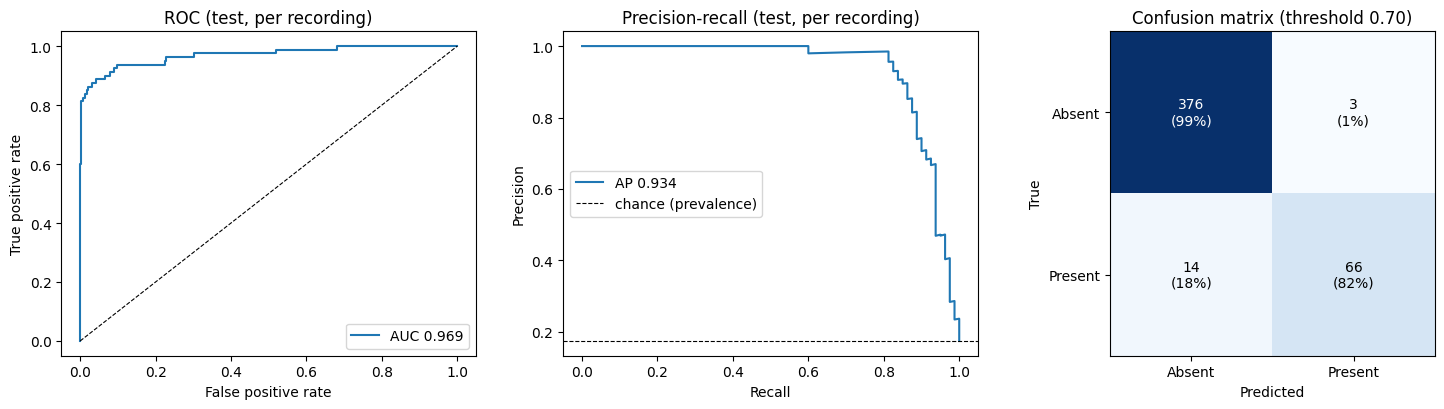

In [15]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.2))

fpr, tpr, _ = roc_curve(rte_y, rte_p)
axs[0].plot(fpr, tpr, label=f"AUC {roc_auc_score(rte_y, rte_p):.3f}"); axs[0].plot([0, 1], [0, 1], "k--", lw=0.8)
axs[0].set_xlabel("False positive rate"); axs[0].set_ylabel("True positive rate"); axs[0].set_title("ROC (test, per recording)"); axs[0].legend()

prec, rec, _ = precision_recall_curve(rte_y, rte_p)
axs[1].plot(rec, prec, label=f"AP {average_precision_score(rte_y, rte_p):.3f}")
axs[1].axhline(rte_y.mean(), color="k", ls="--", lw=0.8, label="chance (prevalence)")
axs[1].set_xlabel("Recall"); axs[1].set_ylabel("Precision"); axs[1].set_title("Precision-recall (test, per recording)"); axs[1].legend()

cm = confusion_matrix(rte_y, pred)
axs[2].imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        axs[2].text(j, i, f"{cm[i, j]}\n({cm[i, j] / cm[i].sum():.0%})", ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
axs[2].set_xticks([0, 1]); axs[2].set_xticklabels(["Absent", "Present"]); axs[2].set_yticks([0, 1]); axs[2].set_yticklabels(["Absent", "Present"])
axs[2].set_xlabel("Predicted"); axs[2].set_ylabel("True"); axs[2].set_title(f"Confusion matrix (threshold {thr:.2f})")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig5_test_roc_pr_confusion.png", dpi=150); plt.show()

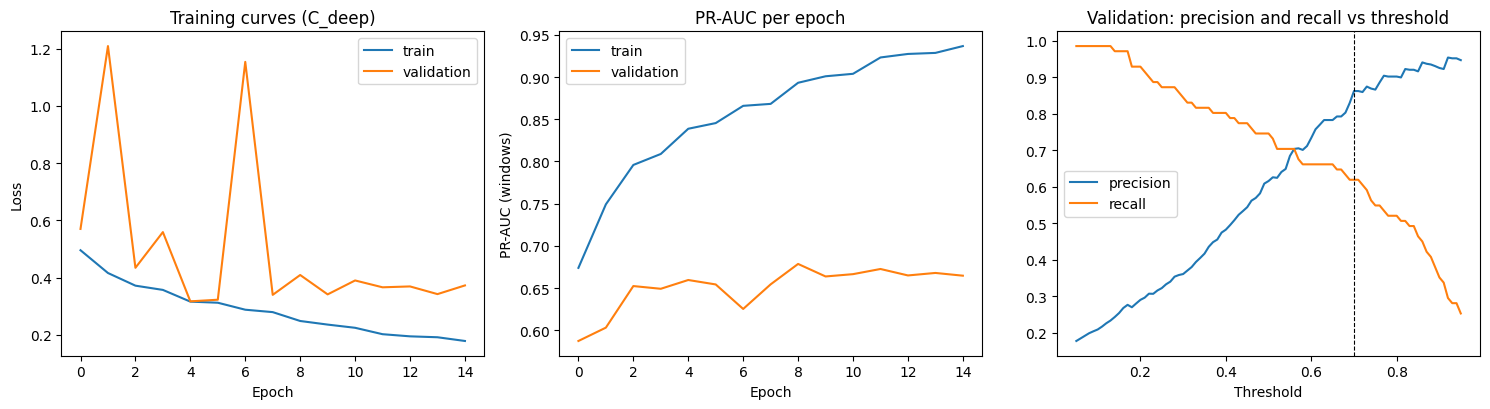

In [16]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.2))
H = hist.history
axs[0].plot(H["loss"], label="train"); axs[0].plot(H["val_loss"], label="validation")
axs[0].set_xlabel("Epoch"); axs[0].set_ylabel("Loss"); axs[0].set_title(f"Training curves ({best_name})"); axs[0].legend()
axs[1].plot(H["pr_auc"], label="train"); axs[1].plot(H["val_pr_auc"], label="validation")
axs[1].set_xlabel("Epoch"); axs[1].set_ylabel("PR-AUC (windows)"); axs[1].set_title("PR-AUC per epoch"); axs[1].legend()

ps = [precision_score(rva_y, rva_p >= t, zero_division=0) for t in grid]
rs = [recall_score(rva_y, rva_p >= t) for t in grid]
axs[2].plot(grid, ps, label="precision"); axs[2].plot(grid, rs, label="recall"); axs[2].axvline(thr, color="k", ls="--", lw=0.8)
axs[2].set_xlabel("Threshold"); axs[2].set_title("Validation: precision and recall vs threshold"); axs[2].legend()
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig6_training_and_threshold.png", dpi=150); plt.show()

## Export
Packages the model, data samples, demo recordings, figures and result tables into one zip.
Download only `export.zip`, and unzip it once.

In [17]:
EXP = "/kaggle/working/export"
shutil.rmtree(EXP, ignore_errors=True)
for d in ["models", "data/train", "data/test", "results", "figures"]:
    os.makedirs(f"{EXP}/{d}")

# model + state (threshold is the validation-selected one for this model)
model.save(f"{EXP}/models/murmur_cnn_v1.keras")
cfg_out = {"threshold": thr, "sr": P.SR, "win_sec": P.WIN_SEC, "n_mels": P.N_MELS,
           "input_shape": list(Xtr.shape[1:]), "architecture": best_name, "label_rule_restrict_to_murmur_locations": RESTRICT_TO_MURMUR_LOCATIONS}
json.dump(cfg_out, open(f"{EXP}/models/config.json", "w"), indent=2)
json.dump({"version": 1, "model_file": "murmur_cnn_v1.keras", "threshold": thr, "history": [], "used_batches": []},
          open(f"{EXP}/models/state.json", "w"), indent=2)

# small balanced samples used by the retraining code in the deployed app
rs_ = np.random.default_rng(SEED)
def balanced_sample(X, y, n):
    idx = np.concatenate([rs_.choice(np.where(y == c)[0], min(n, int((y == c).sum())), replace=False) for c in (0., 1.)])
    return X[idx], y[idx]
Xs, ys = balanced_sample(Xtr, ytr, 400); np.savez_compressed(f"{EXP}/data/train/train_sample.npz", X=Xs, y=ys)
Xs, ys = balanced_sample(Xva, yva, 200); np.savez_compressed(f"{EXP}/data/test/val_sample.npz", X=Xs, y=ys)

# demo recordings from test patients: present/ and absent/ folders
test_recs = recs[recs.split == "test"]
for lab, name in [(1, "present"), (0, "absent")]:
    os.makedirs(f"{EXP}/demo_bundle/{name}", exist_ok=True)
    pool = test_recs[test_recs.label == lab]
    for _, r in pool.sample(min(30, len(pool)), random_state=SEED).iterrows():
        shutil.copy(r.path, f"{EXP}/demo_bundle/{name}/{os.path.basename(r.path)}")

recs.drop(columns=["path"]).to_csv(f"{EXP}/recordings.csv", index=False)
for f in os.listdir(FIG_DIR): shutil.copy(f"{FIG_DIR}/{f}", f"{EXP}/figures/{f}")
for f in os.listdir("/kaggle/working/results"): shutil.copy(f"/kaggle/working/results/{f}", f"{EXP}/results/{f}")

shutil.make_archive("/kaggle/working/export", "zip", EXP)
print("export.zip:", round(os.path.getsize("/kaggle/working/export.zip") / 1e6, 1), "MB")

export.zip: 32.4 MB
